# Points of Interest (POIs)
Dr. Jorge Celis 
October, 2024

## Libraries

In [4]:
import matplotlib.pyplot as plt
import geopandas as gpd
import pandas as pd
import requests

In [7]:
# Here is the updated Python script to include gas stations in the Overpass API query:

# Define the Overpass API endpoint
overpass_url = "http://overpass-api.de/api/interpreter"

# Define the Overpass QL query to fetch hardware stores, supermarkets, and gas stations in California
overpass_query = """
[out:json];
area["name"="California"]->.searchArea;
(
  node["shop"="hardware"](area.searchArea);
  node["shop"="supermarket"](area.searchArea);
  node["amenity"="fuel"](area.searchArea);
);
out body;
"""

# Send the request to the Overpass API
response = requests.get(overpass_url, params={'data': overpass_query})
data = response.json()

# Parse the response to extract POIs
pois = []
for element in data['elements']:
    if 'lat' in element and 'lon' in element:
        # Determine the type of POI (hardware, supermarket, or gas station)
        poi_type = element['tags'].get('shop', element['tags'].get('amenity', 'N/A'))
        poi = {
            'id': element['id'],
            'name': element['tags'].get('name', 'N/A'),
            'type': poi_type,
            'lat': element['lat'],
            'lon': element['lon']
        }
        pois.append(poi)

# Convert the list of POIs into a pandas DataFrame
pois_df = pd.DataFrame(pois)

# Display the first few rows of the POI data
pois_df.head()

# Optional: Save the data to a CSV file
pois_df.to_csv('california_POIs.csv', index=False)

print("Data fetched and saved successfully!")

Data fetched and saved successfully!


In [8]:
# Get info about the DataFrame
df_info = pois_df.info()

# Display the first few rows of the DataFrame to check attributes
df_head = pois_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5743 entries, 0 to 5742
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5743 non-null   int64  
 1   name    5743 non-null   object 
 2   type    5743 non-null   object 
 3   lat     5743 non-null   float64
 4   lon     5743 non-null   float64
dtypes: float64(2), int64(1), object(2)
memory usage: 224.5+ KB


<Figure size 1000x1000 with 0 Axes>

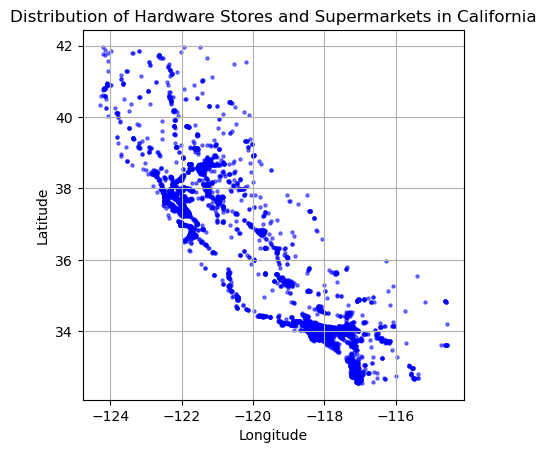

(None,
           id                 name         type        lat         lon
 0   97044219  Circle K & Minimart         fuel  34.057365 -117.190777
 1   98659556                 Arco         fuel  34.048575 -117.225608
 2  140103093                  N/A         fuel  34.041402 -117.156344
 3  150943454   California Oranges  supermarket  36.101236 -118.828068
 4  174130096                 Arco         fuel  37.768468 -122.420268)

In [9]:
# Create a GeoDataFrame for mapping purposes
gdf = gpd.GeoDataFrame(pois_df, geometry=gpd.points_from_xy(pois_df.lon, pois_df.lat))

# Plotting the POIs on a map
plt.figure(figsize=(10, 10))
gdf.plot(marker='o', color='blue', markersize=5, alpha=0.5)
plt.title('Distribution of Hardware Stores and Supermarkets in California')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

df_info, df_head

# Classification

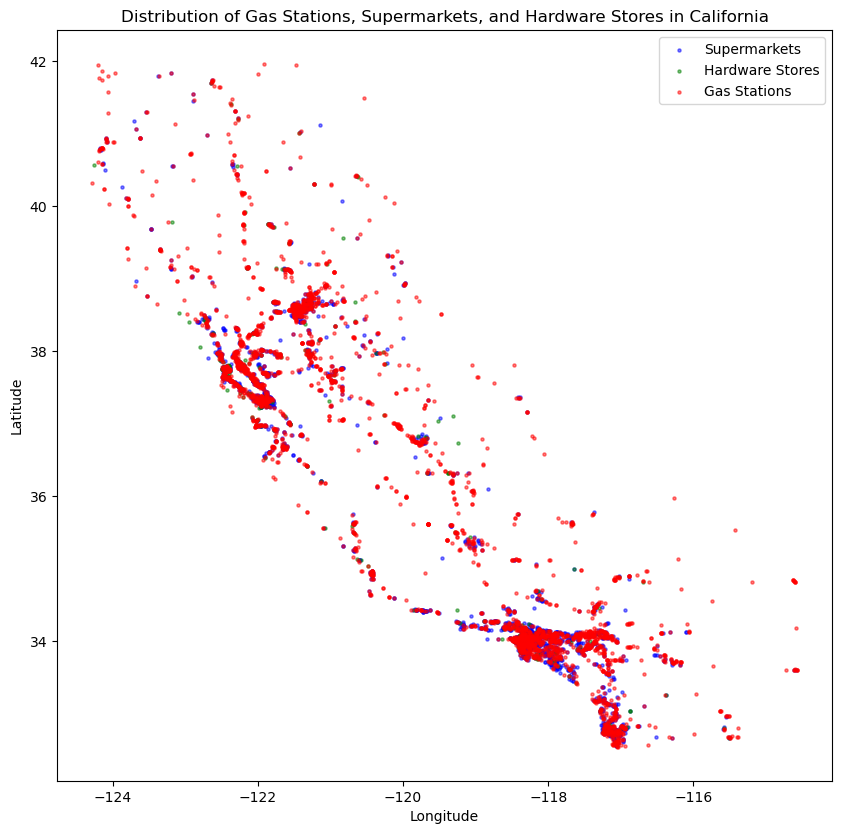

type
fuel                      3295
supermarket               2023
hardware                   303
convenience                 97
convenience;car_repair      12
car_repair                   5
yes                          3
no                           2
gift                         1
gas                          1
alcohol                      1
Name: count, dtype: int64


In [12]:
# Count the number of entries per class (type of POI)
poi_counts = pois_df['type'].value_counts()

# Set up a color scheme for the POI types
colors = {'supermarket': 'blue', 'hardware': 'green', 'fuel': 'red'}

# Filter each type of POI for separate plotting
supermarkets = gdf[gdf['type'] == 'supermarket']
hardware_stores = gdf[gdf['type'] == 'hardware']
gas_stations = gdf[gdf['type'] == 'fuel']

# Plot the map
fig, ax = plt.subplots(figsize=(10, 10))

# Plot each POI type in a different color
supermarkets.plot(ax=ax, marker='o', color=colors['supermarket'], markersize=5, label='Supermarkets', alpha=0.5)
hardware_stores.plot(ax=ax, marker='o', color=colors['hardware'], markersize=5, label='Hardware Stores', alpha=0.5)
gas_stations.plot(ax=ax, marker='o', color=colors['fuel'], markersize=5, label='Gas Stations', alpha=0.5)

# Set plot title and labels
plt.title('Distribution of Gas Stations, Supermarkets, and Hardware Stores in California')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Add a legend
plt.legend()

# Show the plot
plt.show()

# Display the number of entries per class
print(poi_counts)

# Data filtering

Remove non-relevant categories that had been included and group convenience store data points with supermarkets, given its similar nature in responding to severe weather and ARs.

/glade/derecho/scratch/jcelis/tmp/ipykernel_46346/2053618887.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  relevant_pois['type'] = relevant_pois['type'].replace('convenience', 'supermarket')


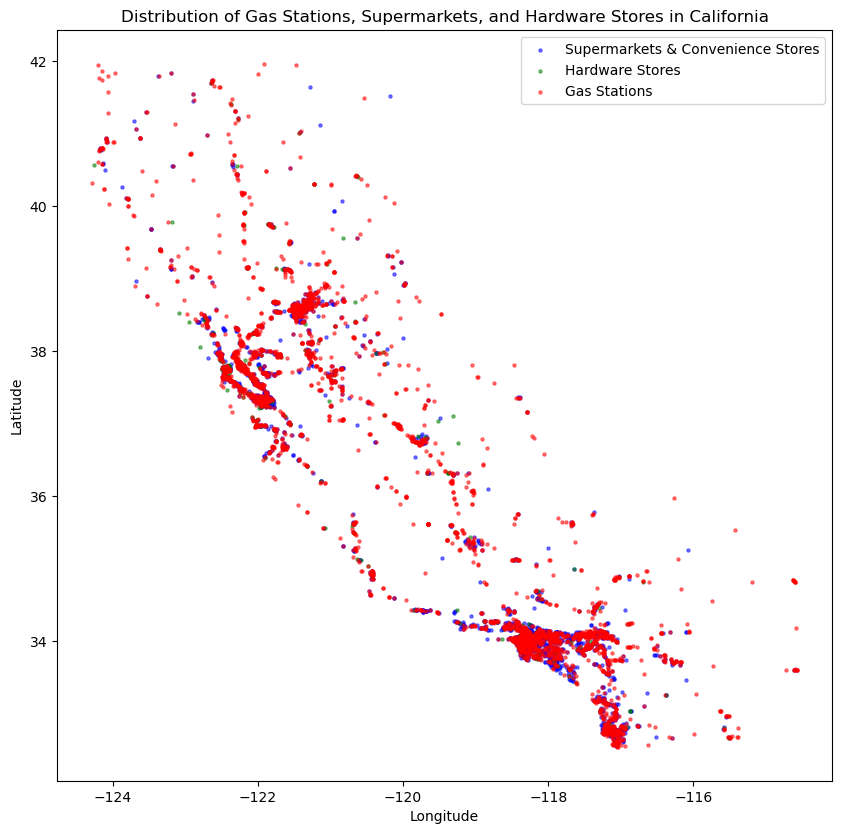

type
fuel           3295
supermarket    2120
hardware        303
Name: count, dtype: int64


In [15]:
# Filter the dataset to include relevant POI types (supermarket, hardware, fuel, convenience)
relevant_pois = pois_df[pois_df['type'].isin(['supermarket', 'hardware', 'fuel', 'convenience'])]

# Combine 'convenience' with 'supermarket'
relevant_pois['type'] = relevant_pois['type'].replace('convenience', 'supermarket')

# Count the number of entries per class (type of POI) after filtering and merging
poi_counts_filtered = relevant_pois['type'].value_counts()

# Plot the map with different colors for each POI class after filtering
import matplotlib.pyplot as plt
import geopandas as gpd

# Create a GeoDataFrame for the filtered POIs
gdf_filtered = gpd.GeoDataFrame(relevant_pois, geometry=gpd.points_from_xy(relevant_pois.lon, relevant_pois.lat))

# Set up colors for different POI types
colors = {'supermarket': 'blue', 'hardware': 'green', 'fuel': 'red'}

# Filter each type of POI for separate plotting
supermarkets = gdf_filtered[gdf_filtered['type'] == 'supermarket']
hardware_stores = gdf_filtered[gdf_filtered['type'] == 'hardware']
gas_stations = gdf_filtered[gdf_filtered['type'] == 'fuel']

# Plot the map
fig, ax = plt.subplots(figsize=(10, 10))

# Plot each POI type in a different color
supermarkets.plot(ax=ax, marker='o', color=colors['supermarket'], markersize=5, label='Supermarkets & Convenience Stores', alpha=0.5)
hardware_stores.plot(ax=ax, marker='o', color=colors['hardware'], markersize=5, label='Hardware Stores', alpha=0.5)
gas_stations.plot(ax=ax, marker='o', color=colors['fuel'], markersize=5, label='Gas Stations', alpha=0.5)

# Set plot title and labels
plt.title('Distribution of Gas Stations, Supermarkets, and Hardware Stores in California')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

# Add a legend
plt.legend()

# Show the plot
plt.show()

# Display the number of entries per class after filtering and merging
print(poi_counts_filtered)



# Save Files

In [17]:
# Save the poi_counts_filtered as a CSV file
poi_counts_filtered.to_csv('California_filtered_POIs.csv', index=False)

# Set the CRS to WGS84 (EPSG:4326) if not already set
gdf_filtered.set_crs(epsg=4326, inplace=True)

# Save the GeoDataFrame (gdf_filtered) as a shapefile
gdf_filtered.to_file('California_filtered_pois.shp')

# Optionally, save the GeoDataFrame as a GeoJSON
gdf_filtered.to_file('California_filtered_pois.geojson', driver='GeoJSON')

print("Files saved successfully as CSV, Shapefile, and GeoJSON!")


Files saved successfully as CSV, Shapefile, and GeoJSON!


In [1]:
poi_counts_filtered.head()

NameError: name 'poi_counts_filtered' is not defined

In [ ]:
 # Convert the list of POIs into a pandas DataFrame
pois_df = pd.DataFrame(pois)

# Display the first few rows of the POI data
pois_df.head()

# Optional: Save the data to a CSV file
pois_df.to_csv('california_POIs.csv', index=False)

print("Data fetched and saved successfully!")